# Survey validation: DESI, Rubin/LSST, SKAO and Planck

This notebook is a quick companion to `docs/source/survey_validation.md`. It runs a small
subset of the survey forecast comparison (Euclid 3x2pt, Rubin/LSST 3x2pt and DESI ELG
galaxy clustering), checks the observable-level validation, and shows the figures produced
by `scripts/validation/plot_survey_validation.py`.

Everything here uses the GR fiducial and the `symbolic` backend. The full comparison,
including SKAO and Planck and the w0waCDM run, takes a few minutes and is reproduced with
the three commands in the documentation page.

## Setup

In [1]:
import json
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
WORKDIR = Path(tempfile.mkdtemp(prefix="survey_validation_"))
import cosmicjellyfish

_CODE = Path(cosmicjellyfish.__file__).resolve().parent
assert _CODE == REPO_ROOT / "cosmicjellyfish", (
    f"this kernel imports cosmicjellyfish from {_CODE}, not from {REPO_ROOT}; "
    "select the kernel of this worktree (e.g. uv run jupyter lab)."
)
print("Interpreter:", sys.executable)
print("Working directory:", WORKDIR)


Interpreter: /home/santiago/CosmoProjects/cosmicfish_release/cfp-survey/.venv/bin/python
Working directory: /tmp/survey_validation_0_svys2c


## Quick forecast run

Three cases are enough to see the pipeline in action: two photometric surveys with the
same 3x2pt probe combination, and one spectroscopic survey. The script writes a JSON
summary and the Fisher matrices into the working directory.

In [2]:
cases = ["euclid-photo", "rubin-photo", "desi-elg"]
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/validation/run_survey_forecasts.py"),
    "--model",
    "LCDM",
    "--output-dir",
    str(WORKDIR),
]
for case in cases:
    command.extend(["--case", case])
subprocess.run(command, check=True, cwd=REPO_ROOT)


Running Euclid photometric (GCph+WL) ...



  Fisher matrix exported: /tmp/survey_validation_0_svys2c/fishers/CosmicFish_v2.0.0_survey_forecast_lcdm_euclid_photo_GCphWL_FM.txt

Running Rubin/LSST photometric (GCph+WL) ...



  Fisher matrix exported: /tmp/survey_validation_0_svys2c/fishers/CosmicFish_v2.0.0_survey_forecast_lcdm_rubin_photo_GCphWL_FM.txt

Running DESI ELG (GCsp) ...


Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>

  Fisher matrix exported: /tmp/survey_validation_0_svys2c/fishers/CosmicFish_v2.0.0_survey_forecast_lcdm_desi_elg_GCsp_FM.txt


| Case | Omegam | Omegab | h | ns | sigma8 | Time (s) |
| --- | --- | --- | --- | --- | --- | --- |
| Euclid photometric (GCph+WL) | 0.002414 | 0.002182 | 0.01733 | 0.009728 | 0.002995 | 8.7 |
| Rubin/LSST photometric (GCph+WL) | 0.00125 | 0.00199 | 0.01185 | 0.004996 | 0.001591 | 7.7 |
| DESI ELG (GCsp) | 0.005035 | 0.001454 | 0.008439 | 0.009342 | 0.005353 | 11.0 |

Wrote /tmp/survey_validation_0_svys2c/survey_forecasts_LCDM.json
Wrote /tmp/survey_validation_0_svys2c/survey_forecasts_LCDM.md


CompletedProcess(args=['/home/santiago/CosmoProjects/cosmicfish_release/cfp-survey/.venv/bin/python', '/home/santiago/CosmoProjects/cosmicfish_release/cfp-survey/scripts/validation/run_survey_forecasts.py', '--model', 'LCDM', '--output-dir', '/tmp/survey_validation_0_svys2c', '--case', 'euclid-photo', '--case', 'rubin-photo', '--case', 'desi-elg'], returncode=0)

The JSON summary is easy to turn into a table of marginalised errors.

In [3]:
report = json.loads((WORKDIR / "survey_forecasts_LCDM.json").read_text())
rows = [
    {"survey": result["label"], **result["sigma"], "time [s]": round(result["elapsed_s"], 1)}
    for result in report["results"]
]
pd.DataFrame(rows).set_index("survey").style.format(precision=4)

,Omegam,Omegab,h,ns,sigma8,time [s]
survey,,,,,,
Euclid photometric (GCph+WL),0.0024,0.0022,0.0173,0.0097,0.0030,8.7000
Rubin/LSST photometric (GCph+WL),0.0012,0.0020,0.0118,0.0050,0.0016,7.7000
DESI ELG (GCsp),0.0050,0.0015,0.0084,0.0093,0.0054,11.0000


## Observable validation

The validation harness compares the package observables with an independent transcription
of the historical recipes. It needs a local checkout of the SKAO forecast project; if that
is not available, the script reports the missing path instead of failing silently.

In [4]:
result = subprocess.run(
    [
        sys.executable,
        str(REPO_ROOT / "scripts/validation/validate_survey_observables.py"),
        "--output-dir",
        str(WORKDIR),
    ],
    cwd=REPO_ROOT,
)
if result.returncode != 0:
    raise RuntimeError(
        "Observable validation failed. Set COSMICFISH_HISTORICAL_DIR to a checkout "
        "that contains survey_specifications/ and data-for-fig1.dat."
    )


Validating desi-bgs (DESI, gcsp) ...
Validating desi-elg (DESI, gcsp) ...
Validating skao-hi (SKAO, gcsp) ...
Validating skao-im (SKAO, im) ...
Validating skao-im-desi (SKAO, im-cross) ...
Validating rubin-photo (Rubin, photo) ...
Validating skao-photo (SKAO, photo) ...
Validating fig1 (SKAO, fig1) ...
Wrote /tmp/survey_validation_0_svys2c/fig1_diagnostic.json

survey         observable     quantity                    max rel. diff  status
-------------------------------------------------------------------------------
desi-bgs       GCsp           n_density [Mpc^-3]              0.000e+00  ok
desi-bgs       GCsp           volume_survey [Mpc^3]           2.014e-16  ok
desi-bgs       GCsp           fiducial bias                   0.000e+00  ok
desi-bgs       GCsp           P_gg(k, mu, z)                  5.226e-16  ok
desi-elg       GCsp           n_density [Mpc^-3]              1.222e-16  ok
desi-elg       GCsp           volume_survey [Mpc^3]           2.410e-16  ok
desi-elg       GCsp 

In [5]:
rows_path = WORKDIR / "observable_validation.json"
if not rows_path.exists():
    raise FileNotFoundError(
        "observable_validation.json was not written; check the validation run above."
    )
report = json.loads(rows_path.read_text())
frame = pd.DataFrame(report["rows"])
failed = frame[frame["status"] == "check"]
if len(failed):
    raise RuntimeError(f"{len(failed)} observable checks failed:\n{failed.to_string()}")
print(frame["status"].value_counts())
frame.head(12)


status
ok          39
expected     8
Name: count, dtype: int64


,survey,observable,quantity,max_relative_difference,status,note
0,desi-bgs,GCsp,n_density [Mpc^-3],0.000000e+00,ok,
1,desi-bgs,GCsp,volume_survey [Mpc^3],2.013651e-16,ok,
2,desi-bgs,GCsp,fiducial bias,0.000000e+00,ok,
3,desi-bgs,GCsp,"P_gg(k, mu, z)",5.225741e-16,ok,s8-normalised paper form
4,desi-elg,GCsp,n_density [Mpc^-3],1.222200e-16,ok,
5,desi-elg,GCsp,volume_survey [Mpc^3],2.409968e-16,ok,
6,desi-elg,GCsp,fiducial bias,0.000000e+00,ok,
7,desi-elg,GCsp,"P_gg(k, mu, z)",6.647433e-16,ok,s8-normalised paper form
8,skao-hi,GCsp,n_density [Mpc^-3],2.158285e-16,ok,
9,skao-hi,GCsp,volume_survey [Mpc^3],1.409556e-16,ok,


## Survey inputs

The left panel shows the spectroscopic and intensity-mapping number densities; the right
panel shows the analytic photometric `dN/dz` of the three imaging surveys. Both are read
straight from the shipped YAML files, so the figure also documents the migrated
specifications.

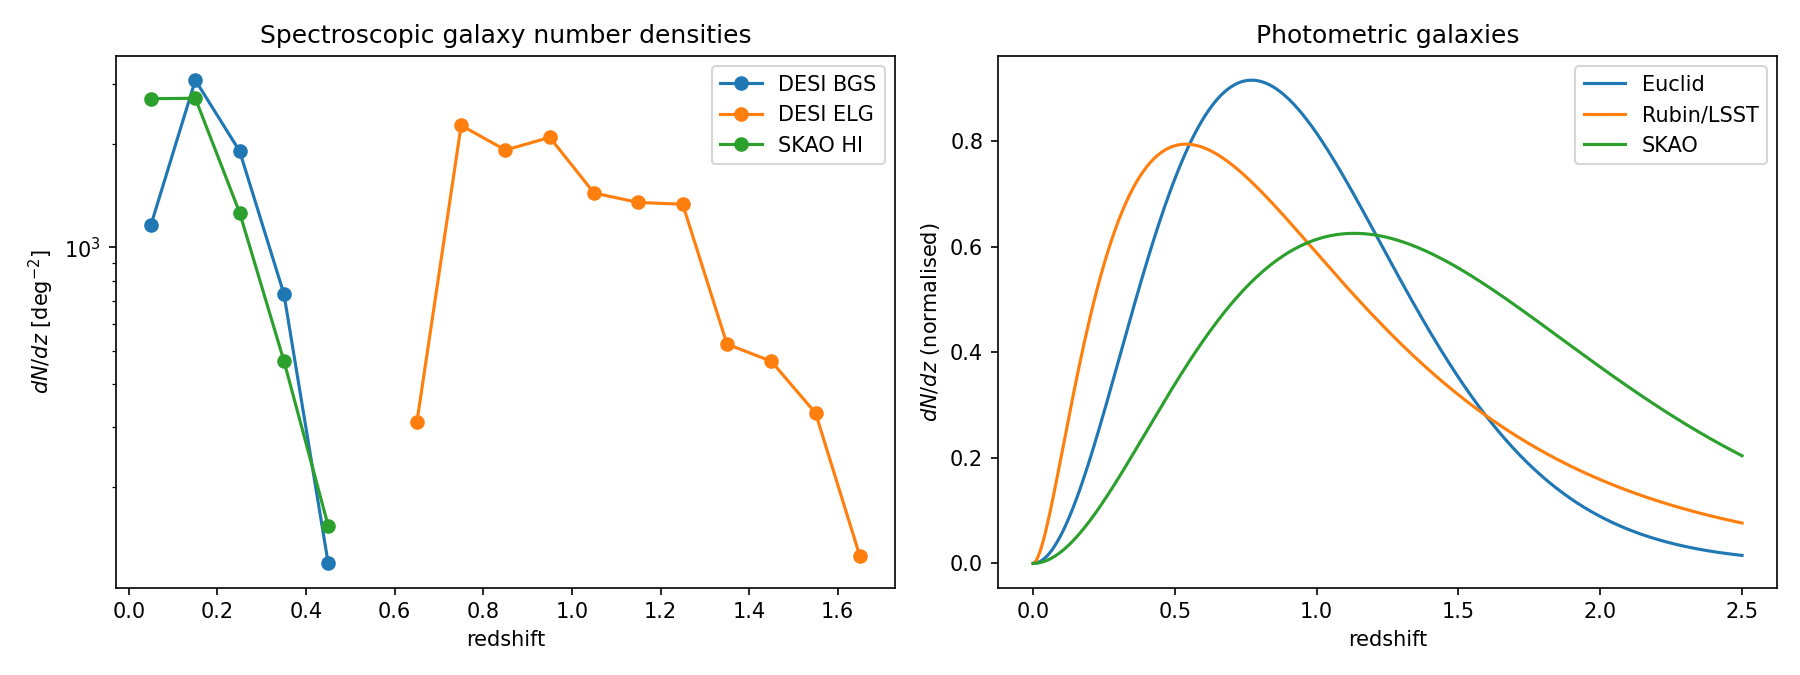

In [6]:
sys.path.insert(0, str(REPO_ROOT / "scripts/validation"))
import plot_survey_validation as plots

figure_path = plots.plot_survey_inputs(WORKDIR)
display(Image(filename=str(figure_path)))

## Full comparison figures

These are the figures committed with the documentation. They come from the complete LCDM
and w0waCDM runs, not from the quick subset above.

forecast_errors.png


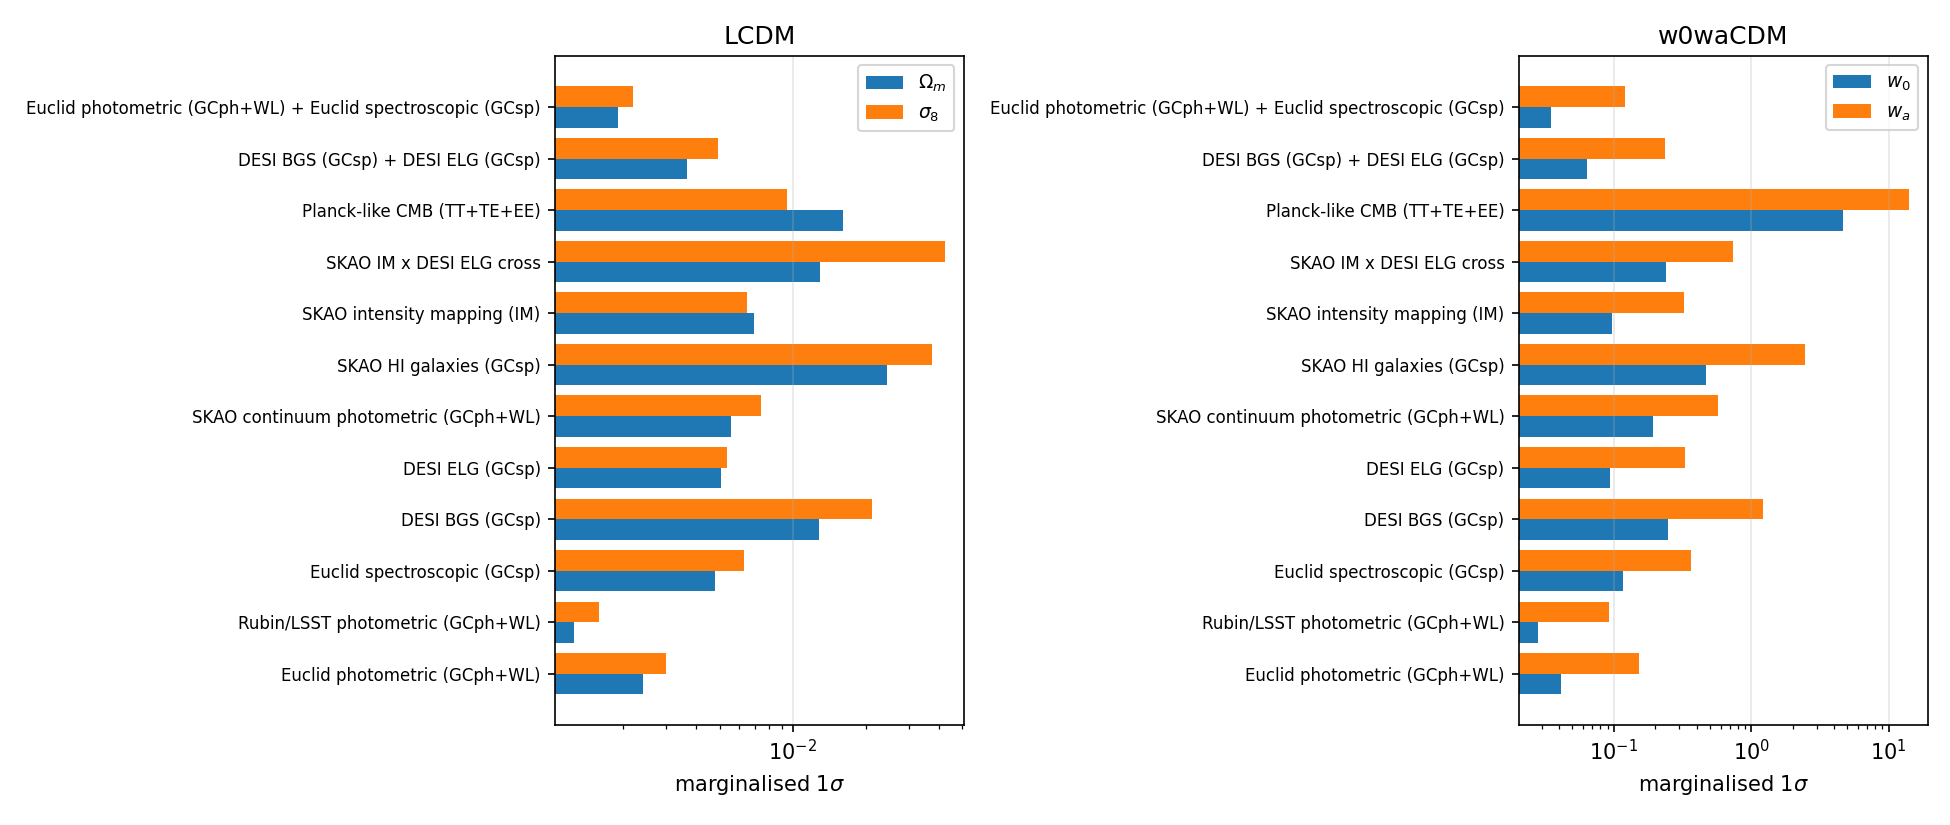

w0wa_comparisons.png


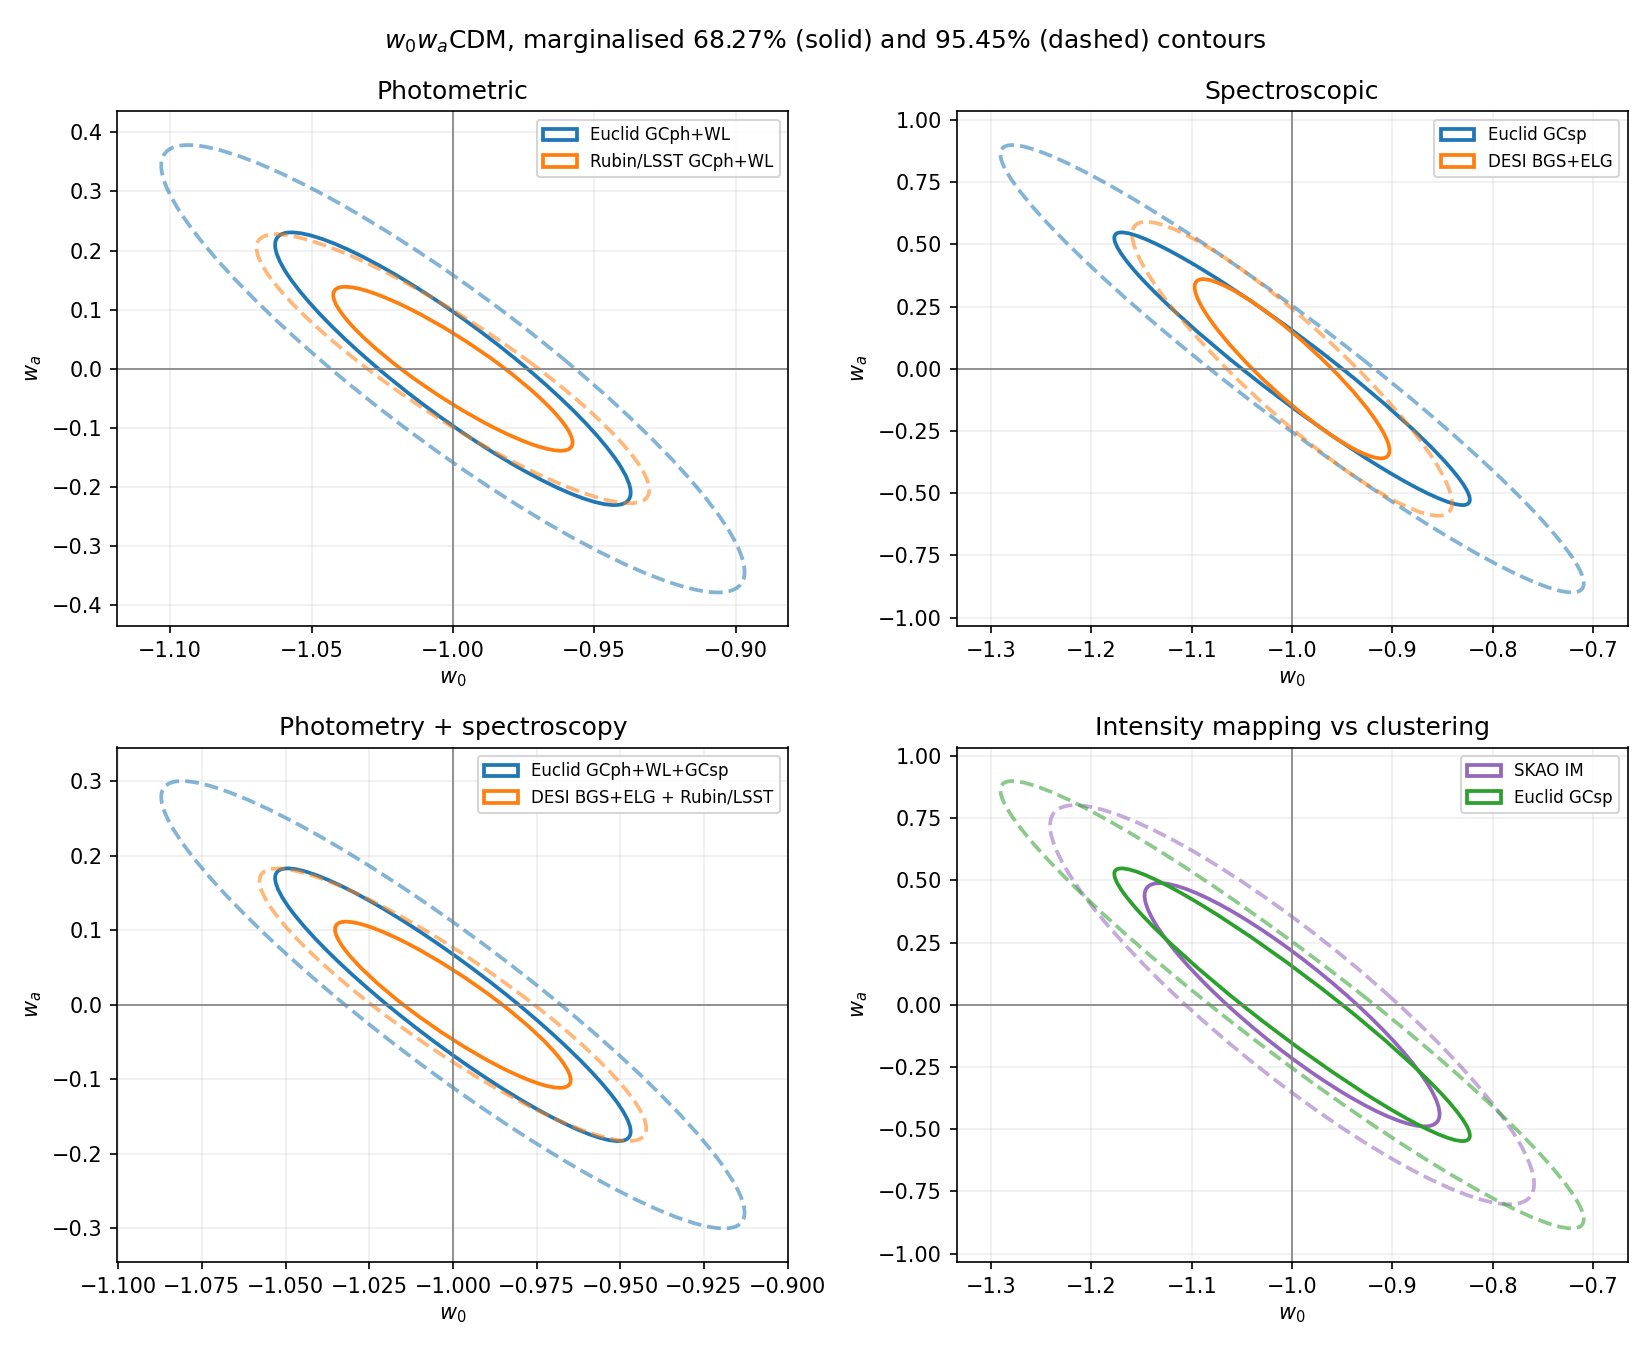

fig1_diagnostic.png


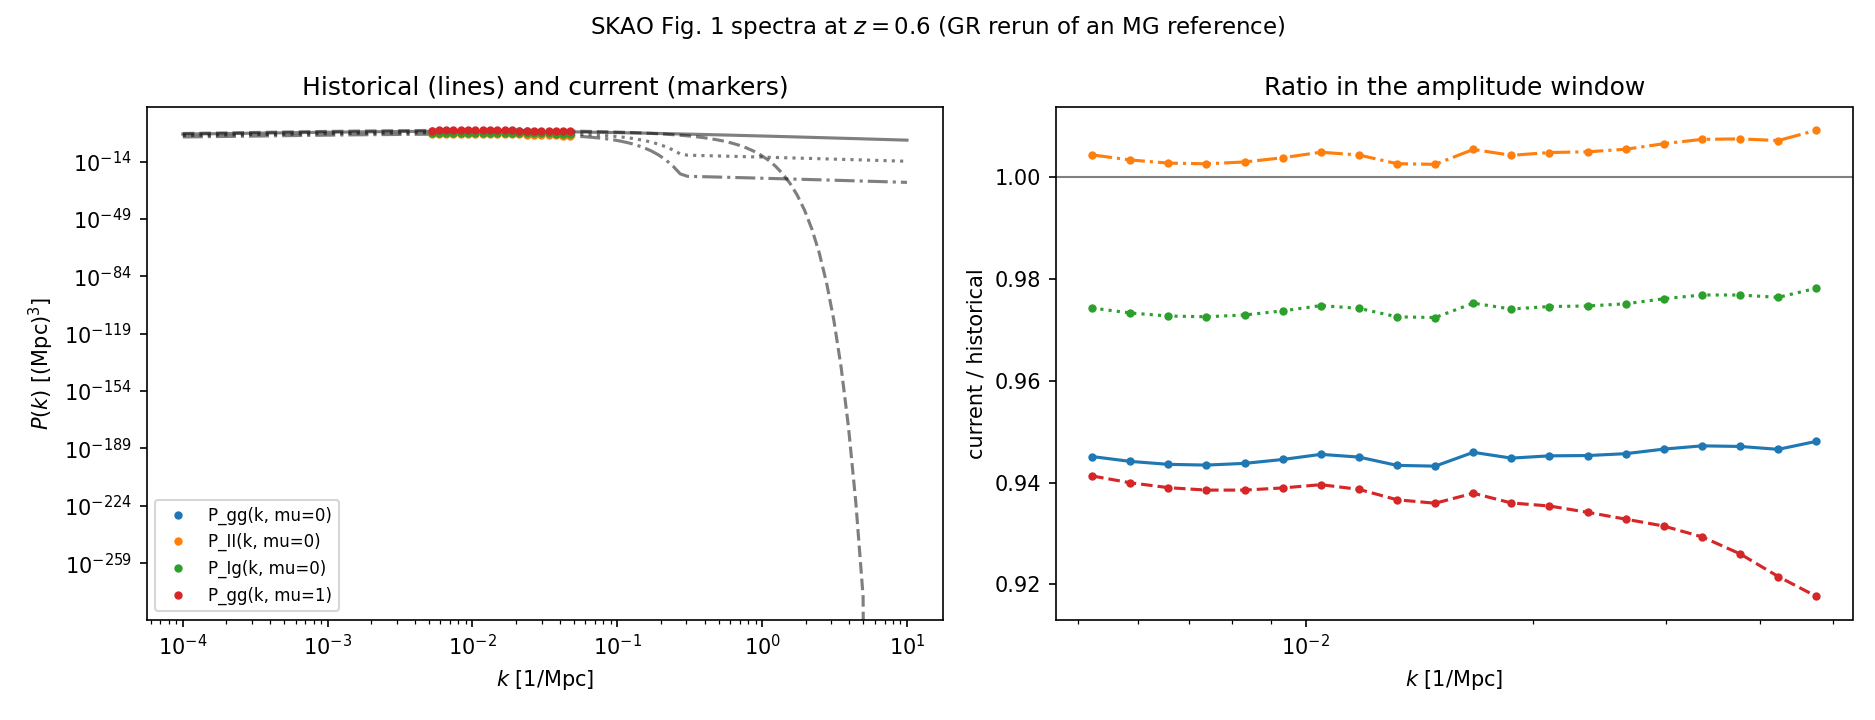

In [7]:
static = REPO_ROOT / "docs/source/_static/survey_validation"
for name in ("forecast_errors.png", "w0wa_comparisons.png", "fig1_diagnostic.png"):
    path = static / name
    if path.exists():
        print(name)
        display(Image(filename=str(path)))
    else:
        print(f"{name} not found; run scripts/validation/plot_survey_validation.py")

## New DESI specifications (2023 validation paper)

The `DESI-BGS-SKAOPaper` and `DESI-ELG-SKAOPaper` files are kept as **legacy** specifications
because they reproduce earlier papers. The `DESI-{BGS,LRG,ELG,QSO}-Validation2023` files are
the updated set, transcribed from Table 7 of DESI Collaboration, *Validation of the Scientific
Program for the Dark Energy Spectroscopic Instrument* (arXiv:2306.06307): surface densities per
$\Delta z = 0.1$ bin over 14,000 deg$^2$ and a bias $b(z) = A/D(z)$ with $A = 1.34, 1.7, 0.84, 1.2$
for BGS, LRG, ELG and QSO. The same recipe is implemented in GoFish
(<https://github.com/ladosamushia/GoFish>), whose input file is not identical to Table 7; Table 7 is
the authority here. The files are produced by `scripts/validation/generate_desi_validation_specs.py`
and the binned bias is the fiducial $A/D(z_\mathrm{mid})$, not a constraint during the Fisher run
(all bin biases remain free nuisance parameters).

In [8]:
DESI_WORKDIR = Path(tempfile.mkdtemp(prefix="desi2023_"))
desi_cases = [
    "desi2023-bgs", "desi2023-lrg", "desi2023-elg", "desi2023-qso",
    "desi-bgs", "desi-elg", "euclid-spectro",
]
for model in ("LCDM", "w0waCDM"):
    command = [
        sys.executable,
        str(REPO_ROOT / "scripts/validation/run_survey_forecasts.py"),
        "--model", model,
        "--output-dir", str(DESI_WORKDIR),
    ]
    for case in desi_cases:
        command.extend(["--case", case])
    subprocess.run(command, check=True, cwd=REPO_ROOT)

Running DESI 2023 BGS (GCsp) ...


Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>

  Fisher matrix exported: /tmp/desi2023_86hyu8hs/fishers/CosmicFish_v2.0.0_survey_forecast_lcdm_desi2023_bgs_GCsp_FM.txt

Running DESI 2023 LRG (GCsp) ...


Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>

  Fisher matrix exported: /tmp/desi2023_86hyu8hs/fishers/CosmicFish_v2.0.0_survey_forecast_lcdm_desi2023_lrg_GCsp_FM.txt

Running DESI 2023 ELG (GCsp) ...


Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>

  Fisher matrix exported: /tmp/desi2023_86hyu8hs/fishers/CosmicFish_v2.0.0_survey_forecast_lcdm_desi2023_elg_GCsp_FM.txt

Running DESI 2023 QSO (GCsp) ...


Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>

  Fisher matrix exported: /tmp/desi2023_86hyu8hs/fishers/CosmicFish_v2.0.0_survey_forecast_lcdm_desi2023_qso_GCsp_FM.txt

Running DESI BGS (GCsp) ...


Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>

  Fisher matrix exported: /tmp/desi2023_86hyu8hs/fishers/CosmicFish_v2.0.0_survey_forecast_lcdm_desi_bgs_GCsp_FM.txt

Running DESI ELG (GCsp) ...


... (6 outputs left out)

Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>

  Fisher matrix exported: /tmp/desi2023_86hyu8hs/fishers/CosmicFish_v2.0.0_survey_forecast_w0wacdm_desi2023_qso_GCsp_FM.txt

Running DESI BGS (GCsp) ...


Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>

  Fisher matrix exported: /tmp/desi2023_86hyu8hs/fishers/CosmicFish_v2.0.0_survey_forecast_w0wacdm_desi_bgs_GCsp_FM.txt

Running DESI ELG (GCsp) ...


Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>

  Fisher matrix exported: /tmp/desi2023_86hyu8hs/fishers/CosmicFish_v2.0.0_survey_forecast_w0wacdm_desi_elg_GCsp_FM.txt

Running Euclid spectroscopic (GCsp) ...


Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>

  Fisher matrix exported: /tmp/desi2023_86hyu8hs/fishers/CosmicFish_v2.0.0_survey_forecast_w0wacdm_euclid_spectro_GCsp_FM.txt


| Case | Omegam | Omegab | h | ns | sigma8 | w0 | wa | Time (s) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| DESI 2023 BGS (GCsp) | 0.02281 | 0.004647 | 0.02835 | 0.04253 | 0.0333 | 0.2854 | 1.41 | 3.2 |
| DESI 2023 LRG (GCsp) | 0.011 | 0.001786 | 0.01465 | 0.01519 | 0.01381 | 0.07687 | 0.2581 | 5.7 |
| DESI 2023 ELG (GCsp) | 0.02957 | 0.00479 | 0.03183 | 0.02003 | 0.02768 | 0.2566 | 0.7286 | 3.8 |
| DESI 2023 QSO (GCsp) | 0.09366 | 0.01637 | 0.1041 | 0.0559 | 0.1026 | 0.8063 | 2.085 | 3.9 |
| DESI BGS (GCsp) | 0.02103 | 0.004178 | 0.02758 | 0.04008 | 0.03119 | 0.249 | 1.207 | 3.7 |
| DESI ELG (GCsp) | 0.01249 | 0.001893 | 0.01507 | 0.01525 | 0.01147 | 0.09367 | 0.3281 | 12.5 |
| Euclid spectroscopic (GCsp) | 0.01431 | 0.002298 | 0.01819 | 0.01396 | 0.01365 | 0.1168 | 0.3

### Inputs: densities and bias versus redshift

Dashed lines are the legacy BGS and ELG files.

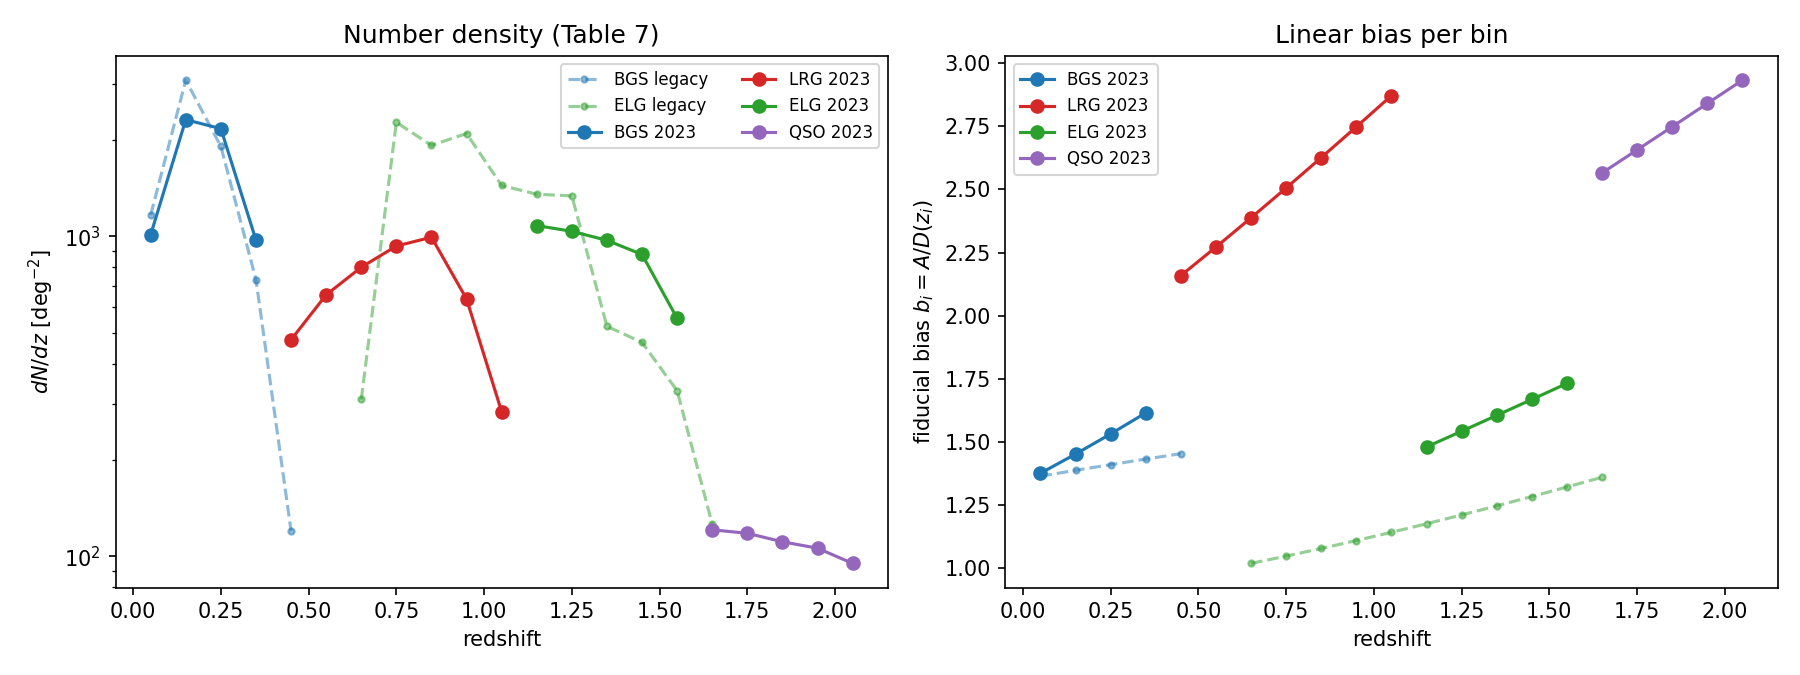

In [9]:
display(Image(filename=str(plots.plot_desi2023_inputs(DESI_WORKDIR))))

### Constraints species by species, and the full 2023 DESI GCsp

Left: each tracer alone in the $w_0$-$w_a$ plane, with the quasars drawn on top. Middle: zoom on
BGS, LRG and ELG. Right: all four tracers combined (independent redshift ranges, so the Fisher
matrices are added) against legacy BGS+ELG and the Euclid spectroscopic sample. All are
galaxy-clustering-only (`GCsp`) forecasts with the symbolic backend.

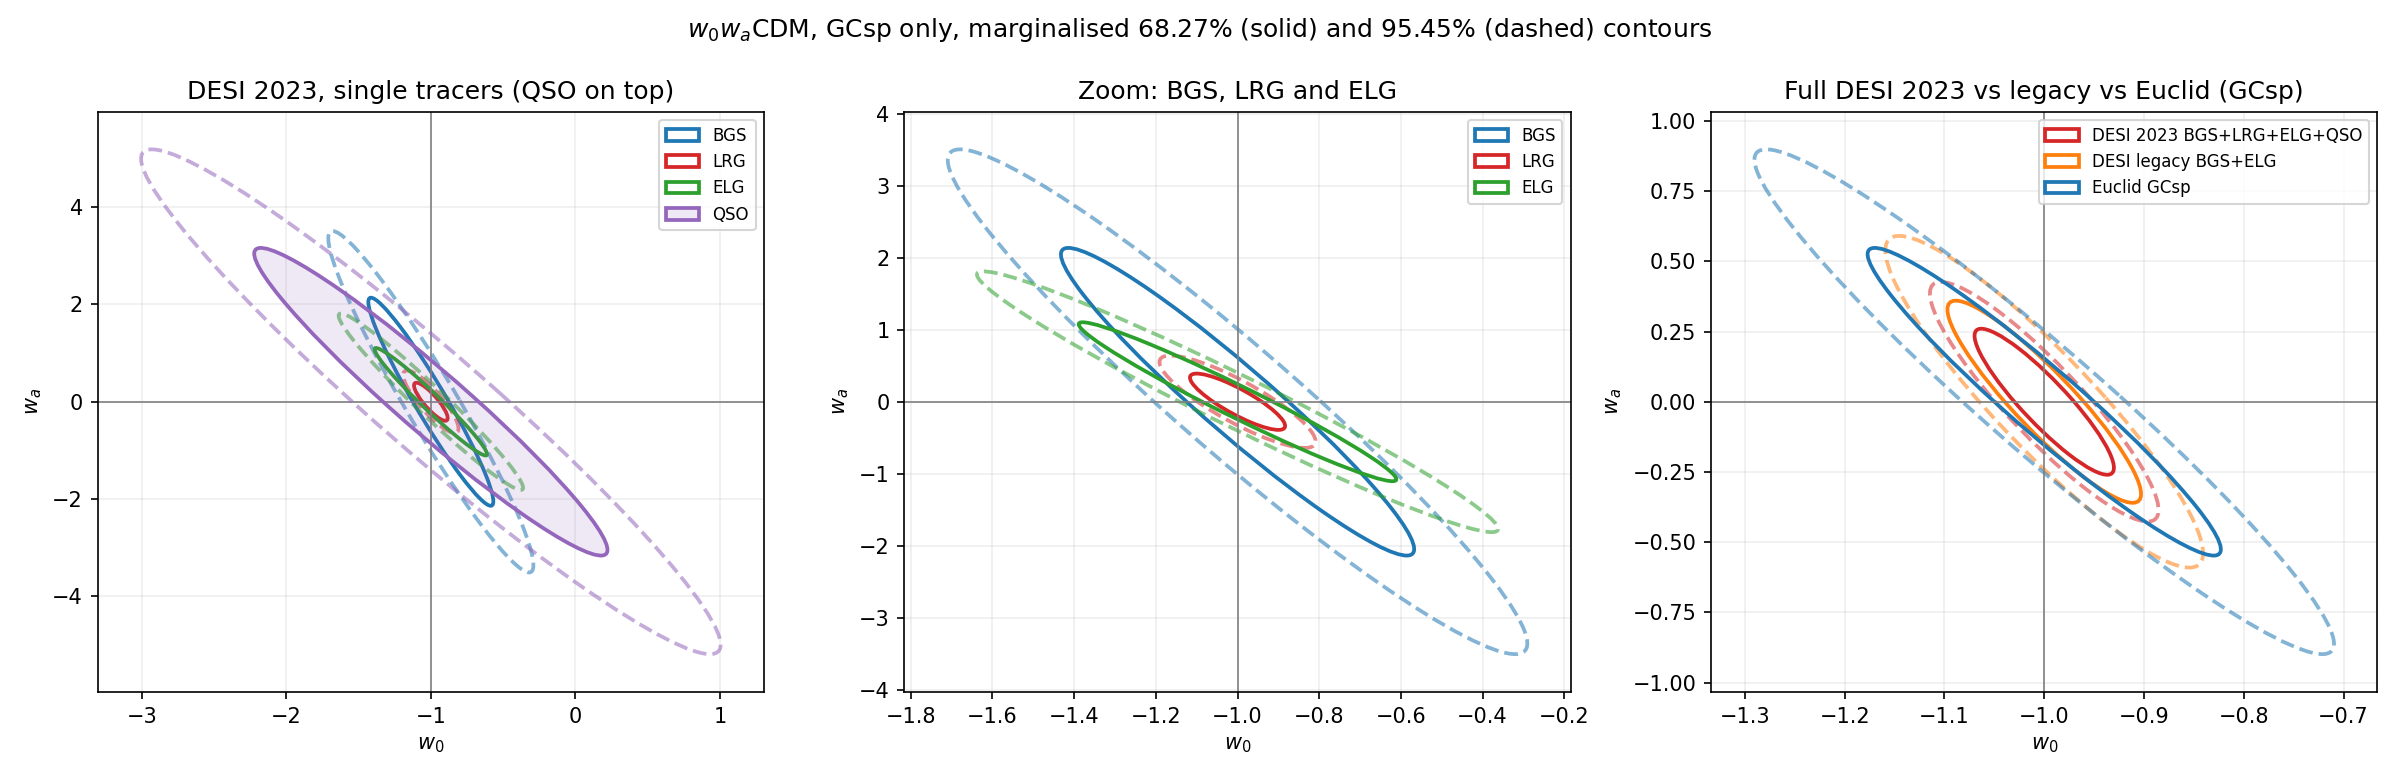

In [10]:
display(Image(filename=str(plots.plot_desi2023_w0wa(DESI_WORKDIR, DESI_WORKDIR))))

### Numbers

Marginal $1\sigma$ errors in flat $\Lambda$CDM, and the $w_0$-$w_a$ errors, relative to the Euclid
spectroscopic sample.

In [11]:
lcdm = json.loads((DESI_WORKDIR / "survey_forecasts_LCDM.json").read_text())
w0wa = json.loads((DESI_WORKDIR / "survey_forecasts_w0waCDM.json").read_text())
w0wa_by_name = {r["name"]: r for r in w0wa["results"]}
reference = {r["name"]: r for r in lcdm["results"]}["euclid-spectro"]["sigma"]
rows = []
for result in lcdm["results"]:
    row = {"case": result["label"], **{k: v for k, v in result["sigma"].items()}}
    row["sigma8 / Euclid"] = result["sigma"]["sigma8"] / reference["sigma8"]
    other = w0wa_by_name.get(result["name"])
    if other is not None:
        row["sigma(w0)"] = other["sigma"]["w0"]
        row["sigma(wa)"] = other["sigma"]["wa"]
    rows.append(row)
pd.DataFrame(rows).set_index("case").style.format(precision=4)

,Omegam,Omegab,h,ns,sigma8,sigma8 / Euclid,sigma(w0),sigma(wa)
case,,,,,,,,
DESI 2023 BGS (GCsp),0.0137,0.0042,0.0183,0.0350,0.0251,3.9995,0.2854,1.4105
DESI 2023 LRG (GCsp),0.0052,0.0014,0.0079,0.0110,0.0107,1.7127,0.0769,0.2581
DESI 2023 ELG (GCsp),0.0080,0.0019,0.0141,0.0122,0.0084,1.3439,0.2566,0.7286
DESI 2023 QSO (GCsp),0.0241,0.0051,0.0489,0.0328,0.0316,5.0453,0.8063,2.0854
DESI BGS (GCsp),0.0128,0.0039,0.0169,0.0330,0.0212,3.3844,0.2490,1.2072
DESI ELG (GCsp),0.0050,0.0015,0.0084,0.0093,0.0054,0.8539,0.0937,0.3281
Euclid spectroscopic (GCsp),0.0048,0.0013,0.0106,0.0090,0.0063,1.0000,0.1168,0.3615
DESI BGS (GCsp) + DESI ELG (GCsp),0.0036,0.0013,0.0062,0.0081,0.0049,0.7833,0.0640,0.2375
DESI 2023 BGS (GCsp) + DESI 2023 LRG (GCsp) + DESI 2023 ELG (GCsp) + DESI 2023 QSO (GCsp),0.0031,0.0010,0.0049,0.0069,0.0056,0.8864,0.0461,0.1716


## What to take away

* The observable algebra (bin densities, bias, volumes, `P_gg`, IM thermodynamics,
  beam, noise and the photometric `dN/dz` and counts) agrees with the independent
  transcription at machine precision. The photometric angular spectra are not
  re-compared against the historical project here.
* The SKAO Fig. 1 spectra agree in shape to better than 1.5% over the calibrated
  range. Their amplitude offset is consistent with the modified-gravity fiducial used
  in the reference, but the comparison does not isolate that from the other
  differences (backend, table extrapolation, modelling).
* On a common GR fiducial the ranking between surveys is driven by the specification
  (sky area, scale cuts, binning), not by the telescope name. The historical Rubin file
  has wider weak-lensing cuts than the shipped Euclid file, so it looks stronger.
* The new DESI specifications (Table 7 of arXiv:2306.06307) add LRG and quasar samples next to
  BGS and ELG and keep the old files as legacy. In GCsp alone the LRG is the strongest single tracer and
  the quasars the weakest; the four samples together are tighter than the legacy BGS+ELG and than the
  Euclid spectroscopic sample. The new bias values differ from the legacy files, but all bin biases
  are free nuisance parameters, and derivative-step sensitivity of these runs has not been scanned.
* The IM x DESI-ELG entry is a cross-spectrum-only Fisher, and the Planck-like entry is
  a single-channel approximation run with CAMB. Neither is a substitute for the real
  likelihoods.
* The published SKAO constraints are on modified-gravity parameters and are out of scope
  here; see `docs/SURVEY_VALIDATION_ROADMAP.md` for the full provenance and caveats.
